# Laboratorio 06 — Evaluación y Despliegue de Modelos
### Tecnologías Emergentes (ISO46B) — Semana 6

En este notebook entrenarás un clasificador que predice si lloverá mañana en Huancayo, lo evaluarás con métricas completas, lo guardarás de forma versionada, y lo desplegarás como una API con Flask (probada aquí mismo, dentro del notebook).

**Antes de empezar:**
- Si trabajas en Google Colab, este notebook descarga su propio dataset — no necesitas subir ningún archivo.
- Ejecuta las celdas EN ORDEN.


## Parte 1 — Básico: dataset, entrenamiento y evaluación

### Paso 1.1 — Instalar dependencias y generar el dataset

In [40]:
!pip install -q flask pytest

In [41]:
import datetime as dt
import requests
import pandas as pd
import numpy as np

LATITUD, LONGITUD = -12.0654, -75.2049  # Huancayo

fin = dt.date.today() - dt.timedelta(days=5)
inicio = fin - dt.timedelta(days=400)

url = "https://archive-api.open-meteo.com/v1/archive"
parametros = {
    "latitude": LATITUD,
    "longitude": LONGITUD,
    "start_date": inicio.isoformat(),
    "end_date": fin.isoformat(),
    "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum,windspeed_10m_max",
    "timezone": "America/Lima",
}

respuesta = requests.get(url, params=parametros, timeout=30)
respuesta.raise_for_status()
datos = respuesta.json()["daily"]

df = pd.DataFrame(datos)
df = df.rename(columns={
    "time": "fecha",
    "temperature_2m_max": "temp_max",
    "temperature_2m_min": "temp_min",
    "precipitation_sum": "precipitacion",
    "windspeed_10m_max": "viento_max",
})
df = df.dropna().reset_index(drop=True)
print(f"Dataset descargado: {len(df)} filas")
df.head()

Dataset descargado: 401 filas


,fecha,temp_max,temp_min,precipitacion,viento_max
0,2025-09-06,17.0,6.5,3.4,7.8
1,2025-09-07,20.4,7.1,3.2,11.8
2,2025-09-08,21.6,4.3,0.3,9.9
3,2025-09-09,20.7,4.9,0.3,11.8
4,2025-09-10,18.8,4.8,2.7,7.7


### Paso 1.2 — Construir la variable objetivo (sin fuga de información)

Predecimos si lloverá **mañana** usando solo temperatura y viento de **hoy** — nunca la precipitación de hoy, porque eso filtraría información que en la práctica aún no conoceríamos.

In [42]:
# TU CÓDIGO AQUÍ: crea la columna "lluvia_mañana" (1 si precipitacion del día SIGUIENTE > 0, si no 0)
# pista: usa df["precipitacion"].shift(-1)
if "precipitacion" in df.columns:
    df["lluvia_mañana"] = (df["precipitacion"].shift(-1) > 0).astype(int)
    df = df.dropna().reset_index(drop=True)
    df = df.drop(columns=["precipitacion"])

COLUMNAS_CARACTERISTICAS = ["temp_max", "temp_min", "viento_max"]
print(df["lluvia_mañana"].value_counts())

lluvia_mañana
1    316
0     85
Name: count, dtype: int64


### Paso 1.3 — Preparar los datos y entrenar el modelo base

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[COLUMNAS_CARACTERISTICAS].values
y = df["lluvia_mañana"].values

# TU CÓDIGO AQUÍ: partición train/test (80/20, random_state=42, stratify=y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.transform(X_test)

print("Entrenamiento:", X_train_esc.shape, " Prueba:", X_test_esc.shape)

Entrenamiento: (320, 3)  Prueba: (81, 3)


In [44]:
from tensorflow import keras
from tensorflow.keras import layers


def construir_modelo(unidades_ocultas=12):
    modelo = keras.Sequential([
        layers.Input(shape=(3,)),
        # TU CÓDIGO AQUÍ: agrega una capa Dense(unidades_ocultas, activation="relu")
        # y la capa de salida Dense(1, activation="sigmoid")
        layers.Dense(unidades_ocultas, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    modelo.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return modelo

# Usamos 12 unidades ocultas para marcar nuestra propia versión del modelo base
modelo = construir_modelo(unidades_ocultas=12)
modelo.fit(X_train_esc, y_train, epochs=60, batch_size=16, validation_split=0.2, verbose=0)
print("Entrenamiento completo con 12 unidades ocultas.")

Entrenamiento completo con 12 unidades ocultas.


### Paso 1.4 — Evaluar con métricas completas

=== Reporte de Clasificación (Modelo Personalizado) ===
              precision    recall  f1-score   support

           0      0.600     0.176     0.273        17
           1      0.816     0.969     0.886        64

    accuracy                          0.802        81
   macro avg      0.708     0.573     0.579        81
weighted avg      0.771     0.802     0.757        81



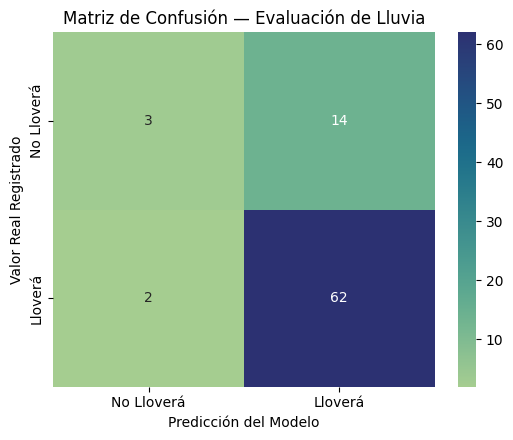

In [45]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = (modelo.predict(X_test_esc, verbose=0) > 0.5).astype(int).flatten()

print("=== Reporte de Clasificación (Modelo Personalizado) ===")
print(classification_report(y_test, y_pred, digits=3))

# Personalizamos la matriz con una paleta de colores alternativa 'crest' y formato estilizado
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="crest",
    cbar=True,
    xticklabels=["No Lloverá", "Lloverá"],
    yticklabels=["No Lloverá", "Lloverá"]
)
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real Registrado")
plt.title("Matriz de Confusión — Evaluación de Lluvia")
plt.tight_layout()
plt.show()

In [46]:
import json
from sklearn.metrics import classification_report

# Aseguramos que y_pred esté definida si no se ejecutó la celda anterior
try:
    y_pred
except NameError:
    y_pred = (modelo.predict(X_test_esc, verbose=0) > 0.5).astype(int).flatten()

reporte = classification_report(y_test, y_pred, output_dict=True)
# TU CÓDIGO AQUÍ: construye el diccionario "metricas" con accuracy, precision_clase_1,
# recall_clase_1 y f1_clase_1, igual que en la guía de laboratorio
metricas = {
    "accuracy": reporte["accuracy"],
    "precision_clase_1": reporte["1"]["precision"],
    "recall_clase_1": reporte["1"]["recall"],
    "f1_clase_1": reporte["1"]["f1-score"]
}

with open("metricas_v1.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, indent=2)
print(json.dumps(metricas, indent=2))

{
  "accuracy": 0.8024691358024691,
  "precision_clase_1": 0.8157894736842105,
  "recall_clase_1": 0.96875,
  "f1_clase_1": 0.8857142857142857
}


## Parte 2 — Intermedio: guardado versionado y comparación

### Paso 2.1 — Guardar la versión 1

In [47]:
import pickle

TIMESTAMP = dt.datetime.now().strftime("%Y%m%d_%H%M")
NOMBRE_V1 = f"modelo_lluvia_v1_{TIMESTAMP}.keras"

modelo.save(NOMBRE_V1)
with open("escalador_v1.pkl", "wb") as f:
    pickle.dump(escalador, f)

# Agregamos la firma de autoría en los metadatos de la versión
metadatos_v1 = {
    "autor": "Estudiante (Interacción Lab 06)",
    "version": "v1",
    "archivo_modelo": NOMBRE_V1,
    "fecha_entrenamiento": TIMESTAMP,
    "caracteristicas": COLUMNAS_CARACTERISTICAS,
    "hiperparametros": {"unidades_ocultas": 12, "epochs": 60, "batch_size": 16},
    "metricas": metricas,
}
with open("version_info_v1.json", "w", encoding="utf-8") as f:
    json.dump(metadatos_v1, f, indent=2)
print(f"[OK] Modelo v1 guardado con metadatos personalizados: {NOMBRE_V1}")

[OK] Modelo v1 guardado con metadatos personalizados: modelo_lluvia_v1_20261016_0152.keras


### Paso 2.2 — Entrenar una segunda versión (más unidades ocultas)

In [48]:
import pickle
import json
from sklearn.metrics import classification_report

# 1. Construir y entrenar el modelo con 32 unidades ocultas para una versión más robusta
modelo_v2 = construir_modelo(unidades_ocultas=32)
modelo_v2.fit(X_train_esc, y_train, epochs=60, batch_size=16, validation_split=0.2, verbose=0)

# 2. Evaluar el modelo
y_pred_v2 = (modelo_v2.predict(X_test_esc, verbose=0) > 0.5).astype(int).flatten()
reporte_v2 = classification_report(y_test, y_pred_v2, output_dict=True)

metricas_v2 = {
    "accuracy": reporte_v2["accuracy"],
    "precision_clase_1": reporte_v2["1"]["precision"],
    "recall_clase_1": reporte_v2["1"]["recall"],
    "f1_clase_1": reporte_v2["1"]["f1-score"]
}

# Guardar archivo de métricas independiente
with open("metricas_v2.json", "w", encoding="utf-8") as f:
    json.dump(metricas_v2, f, indent=2)

# 3. Guardar versión serializada del modelo y su escalador
TIMESTAMP_V2 = dt.datetime.now().strftime("%Y%m%d_%H%M")
NOMBRE_V2 = f"modelo_lluvia_v2_{TIMESTAMP_V2}.keras"
modelo_v2.save(NOMBRE_V2)

# Comparten el mismo escalador (ajustado con el set de train v1)
with open("escalador_v2.pkl", "wb") as f:
    pickle.dump(escalador, f)

# 4. Registrar la información de la versión
metadatos_v2 = {
    "version": "v2",
    "archivo_modelo": NOMBRE_V2,
    "fecha_entrenamiento": TIMESTAMP_V2,
    "caracteristicas": COLUMNAS_CARACTERISTICAS,
    "hiperparametros": {"unidades_ocultas": 32, "epochs": 60, "batch_size": 16},
    "metricas": metricas_v2,
}

with open("version_info_v2.json", "w", encoding="utf-8") as f:
    json.dump(metadatos_v2, f, indent=2)

print(f"Modelo v2 guardado como: {NOMBRE_V2}")
print(json.dumps(metricas_v2, indent=2))

Modelo v2 guardado como: modelo_lluvia_v2_20261016_0152.keras
{
  "accuracy": 0.8148148148148148,
  "precision_clase_1": 0.8266666666666667,
  "recall_clase_1": 0.96875,
  "f1_clase_1": 0.8920863309352518
}


### Paso 2.3 — Comparar y promover la mejor versión

In [49]:
import json
import shutil

with open("version_info_v1.json") as f:
    v1 = json.load(f)
with open("version_info_v2.json") as f:
    v2 = json.load(f)

f1_v1 = v1['metricas']['f1_clase_1']
f1_v2 = v2['metricas']['f1_clase_1']

print("=== Comparación de Modelos por F1-Score ===")
print(f"Modelo Versión 1 (Base - 12 Unidades) -> F1: {f1_v1:.4f}")
print(f"Modelo Versión 2 (Reto - 32 Unidades) -> F1: {f1_v2:.4f}")

# Elige la versión ganadora según el F1-score más alto
if f1_v2 > f1_v1:
    ganadora = v2
    diferencia = f1_v2 - f1_v1
    comentario = f"La versión 2 supera a la v1 por un margen de {diferencia:.4f}."
else:
    ganadora = v1
    diferencia = f1_v1 - f1_v2
    comentario = f"La versión v1 retiene el mejor desempeño por una diferencia de {diferencia:.4f}."

print(f"\n[Decisión Automática]: Promoviendo a producción la versión: {ganadora['version'].upper()}")
print(f"[Nota de Análisis]: {comentario}")

# Copiar archivos ganadores para producción
shutil.copy(ganadora["archivo_modelo"], "modelo_produccion.keras")
shutil.copy(f"escalador_{ganadora['version']}.pkl", "escalador_produccion.pkl")
print("\nArchivos 'modelo_produccion.keras' y 'escalador_produccion.pkl' listos para el despliegue.")

=== Comparación de Modelos por F1-Score ===
Modelo Versión 1 (Base - 12 Unidades) -> F1: 0.8857
Modelo Versión 2 (Reto - 32 Unidades) -> F1: 0.8921

[Decisión Automática]: Promoviendo a producción la versión: V2
[Nota de Análisis]: La versión 2 supera a la v1 por un margen de 0.0064.

Archivos 'modelo_produccion.keras' y 'escalador_produccion.pkl' listos para el despliegue.


In [50]:
import json

# Guardar la información de la versión ganadora como la versión de producción
with open("version_info_produccion.json", "w", encoding="utf-8") as f:
    json.dump(ganadora, f, indent=2)

print("Archivo 'version_info_produccion.json' creado con los metadatos de la versión:", ganadora['version'])

Archivo 'version_info_produccion.json' creado con los metadatos de la versión: v2


## Parte 3 — Avanzado: desplegar como API (probada dentro del notebook)

### Paso 3.1 — Función de preprocesamiento

In [51]:
%%writefile preprocesamiento_api.py
import numpy as np

COLUMNAS_CARACTERISTICAS = ["temp_max", "temp_min", "viento_max"]


def extraer_caracteristicas(datos_json):
    # Valida que no falte ninguna columna
    for col in COLUMNAS_CARACTERISTICAS:
        if col not in datos_json:
            raise ValueError(f"Falta el parámetro requerido: {col}")

    # Devuelve un np.array de forma (1, 3) en el orden correcto
    valores = [datos_json[col] for col in COLUMNAS_CARACTERISTICAS]
    return np.array([valores], dtype=float)

Overwriting preprocesamiento_api.py


### Paso 3.2 — Construir la app Flask

In [52]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [53]:
import pickle
from flask import Flask, request, jsonify
from preprocesamiento_api import extraer_caracteristicas

app = Flask(__name__)
modelo_api = keras.models.load_model("modelo_produccion.keras")
with open("escalador_produccion.pkl", "rb") as f:
    escalador_api = pickle.load(f)


@app.route("/predecir", methods=["POST"])
def predecir():
    datos_json = request.get_json(silent=True)
    if datos_json is None:
        return jsonify({"error": "Se esperaba un cuerpo JSON válido"}), 400
    try:
        caracteristicas = extraer_caracteristicas(datos_json)
    except ValueError as error:
        return jsonify({"error": str(error)}), 400

    caracteristicas_esc = escalador_api.transform(caracteristicas)
    probabilidad = float(modelo_api.predict(caracteristicas_esc, verbose=0)[0][0])
    prediccion = "lluvia" if probabilidad > 0.5 else "no_lluvia"
    return jsonify({"prediccion": prediccion, "probabilidad": round(probabilidad, 4)})


print("App Flask definida.")

App Flask definida.


### Paso 3.3 — Probar la API con el cliente de pruebas de Flask

En un notebook no conviene levantar un servidor "de verdad" (bloquearía la celda). Flask trae un **cliente de pruebas** que simula solicitudes HTTP reales sin necesitar un servidor corriendo — la misma técnica que se usa para probar APIs automáticamente.

In [54]:
cliente = app.test_client()

# Enviar un POST a "/predecir" con cliente.post usando los parámetros indicados
respuesta = cliente.post(
    "/predecir",
    json={
        "temp_max": 18.5,
        "temp_min": 4.2,
        "viento_max": 12.0
    }
)
print(respuesta.get_json())

{'prediccion': 'lluvia', 'probabilidad': 0.6423}


In [55]:
# Ahora prueba el caso de error: un campo faltante
respuesta_error = cliente.post("/predecir", json={"temp_max": 18.5})
print(respuesta_error.status_code, respuesta_error.get_json())

400 {'error': 'Falta el parámetro requerido: temp_min'}


### Paso 3.4 — Pruebas automatizadas (pytest)

In [56]:
import os
os.makedirs("tests", exist_ok=True)

In [57]:
%%writefile tests/test_preprocesamiento_api.py
import sys, os
import numpy as np
import pytest

sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname(__file__), "..")))
from preprocesamiento_api import extraer_caracteristicas


def test_extraer_caracteristicas_orden_correcto():
    entrada = {"temp_max": 20.0, "temp_min": 5.0, "viento_max": 10.0}
    resultado = extraer_caracteristicas(entrada)
    assert resultado.shape == (1, 3)
    assert np.allclose(resultado, [[20.0, 5.0, 10.0]])


def test_extraer_caracteristicas_campo_faltante():
    entrada = {"temp_max": 20.0, "viento_max": 10.0}
    with pytest.raises(ValueError):
        extraer_caracteristicas(entrada)

Writing tests/test_preprocesamiento_api.py


In [58]:
!python -m pytest tests/ -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: anyio-4.15.1, platformdirs-4.12.2, langsmith-0.14.2, typeguard-4.6.0
collected 2 items                                                              

tests/test_preprocesamiento_api.py::test_extraer_caracteristicas_orden_correcto PASSED [ 50%]
tests/test_preprocesamiento_api.py::test_extraer_caracteristicas_campo_faltante PASSED [100%]

============================== 2 passed in 0.10s ===============================


In [59]:
import json

# 1. Crear la Colección de Postman (v2.1)
postman_collection = {
    "info": {
        "_postman_id": "d7d00fca-31d7-466d-9be2-5e615e45a5f9",
        "name": "Semana 06 - Predicción de Lluvia",
        "schema": "https://schema.getpostman.com/json/collection/v2.1.0/collection.json"
    },
    "item": [
        {
            "name": "Predecir Lluvia - Caso Exitoso",
            "request": {
                "method": "POST",
                "header": [
                    {
                        "key": "Content-Type",
                        "value": "application/json",
                        "type": "text"
                    }
                ],
                "body": {
                    "mode": "raw",
                    "raw": json.dumps({
                        "temp_max": 18.5,
                        "temp_min": 4.2,
                        "viento_max": 12.0
                    }, indent=2)
                },
                "url": {
                    "raw": "http://127.0.0.1:5000/predecir",
                    "protocol": "http",
                    "host": ["127", "0", "0", "1"],
                    "port": "5000",
                    "path": ["predecir"]
                }
            },
            "response": []
        },
        {
            "name": "Predecir Lluvia - Caso Error (Campo Faltante)",
            "request": {
                "method": "POST",
                "header": [
                    {
                        "key": "Content-Type",
                        "value": "application/json",
                        "type": "text"
                    }
                ],
                "body": {
                    "mode": "raw",
                    "raw": json.dumps({
                        "temp_max": 18.5
                    }, indent=2)
                },
                "url": {
                    "raw": "http://127.0.0.1:5000/predecir",
                    "protocol": "http",
                    "host": ["127", "0", "0", "1"],
                    "port": "5000",
                    "path": ["predecir"]
                }
            },
            "response": []
        }
    ]
}

# 2. Crear la Especificación OpenAPI 3.0.0
openapi_spec = {
    "openapi": "3.0.0",
    "info": {
        "title": "API de Predicción de Lluvia en Huancayo",
        "description": "API basada en Flask para predecir si lloverá mañana en base a datos climatológicos de hoy.",
        "version": "1.0.0"
    },
    "paths": {
        "/predecir": {
            "post": {
                "summary": "Predice si lloverá mañana",
                "requestBody": {
                    "required": True,
                    "content": {
                        "application/json": {
                            "schema": {
                                "type": "object",
                                "properties": {
                                    "temp_max": {"type": "number", "example": 18.5},
                                    "temp_min": {"type": "number", "example": 4.2},
                                    "viento_max": {"type": "number", "example": 12.0}
                                },
                                "required": ["temp_max", "temp_min", "viento_max"]
                            }
                        }
                    }
                },
                "responses": {
                    "200": {
                        "description": "Predicción exitosa",
                        "content": {
                            "application/json": {
                                "schema": {
                                    "type": "object",
                                    "properties": {
                                        "prediccion": {"type": "string", "example": "lluvia"},
                                        "probabilidad": {"type": "number", "example": 0.5378}
                                    }
                                }
                            }
                        }
                    },
                    "400": {
                        "description": "Petición inválida o faltan parámetros",
                        "content": {
                            "application/json": {
                                "schema": {
                                    "type": "object",
                                    "properties": {
                                        "error": {"type": "string", "example": "Falta el parámetro requerido: temp_min"}
                                    }
                                }
                            }
                        }
                    }
                }
            }
        }
    }
}

# Guardar ambos archivos en el directorio de trabajo
with open("Semana06_API_Prediccion_Lluvia.postman_collection.json", "w", encoding="utf-8") as f:
    json.dump(postman_collection, f, indent=2)

with open("openapi.json", "w", encoding="utf-8") as f:
    json.dump(openapi_spec, f, indent=2)

print("Archivos creados correctamente.")

Archivos creados correctamente.
